# 03 · ResNet18: training and behaviour

We first show how ResNet18 was trained, then ask what changes its predictions.
Read the training steps, **Part A: standard figures**, and **Part B: AI-assisted follow-up**.
A short supporting check sits at the bottom.

This revision's code and explanations were edited with AI assistance. Part A contains
standard plots, including the two new lecture-inspired views. Human-only authorship of
the earlier figures is not established.
Part B contains the explicitly AI-assisted investigations. The team interaction log
records individual contributions.

Figures use the recorded experiment, even if you start a new training run. No model
download or training happens during the default Run All.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
# This works when Jupyter opens either the repository or the phase1 folder.
try:
    from phase1 import helpers as h
except ModuleNotFoundError:
    import helpers as h
plt.ioff();  # Display each figure when all its panels are ready.


In [2]:
import json
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(4)
RUN_TRAINING = False  # Run All shows saved results; set True to train again.


## 1. Training setup

Both models use the same audited split: 88,702 training, 10,000 validation and 20,000
official test images. FAKE = 0, REAL = 1. Inputs are RGB pixels scaled to 0–1, with no
random augmentation. The output is one REAL logit; zero is the classification threshold.

The training code is included below. Run All uses saved results. To train again, prepare
`data/baseline_seed1/` with the original root data pipeline and set `RUN_TRAINING = True`.
We select weights by validation loss and never use the test set to choose an epoch.


ResNet18 starts from ImageNet weights. It enlarges each 32×32 image to 224×224,
normalizes with the ImageNet mean and standard deviation, and uses a new one-output
classifier. The first two epochs train only that classifier; then all layers learn.


In [3]:
# Keep preprocessing inside the model so training and inference use the same input.
class CifakeResNet18(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.net = torchvision.models.resnet18(weights=weights)
        self.net.fc = nn.Linear(self.net.fc.in_features, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406])[None, :, None, None])
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225])[None, :, None, None])

    def forward(self, x):
        # Upsampling changes the input size, but creates no new image detail.
        x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False, antialias=True)
        return self.net((x - self.mean) / self.std).squeeze(1)


In [4]:
# The pretrained backbone learns more slowly than the new classifier.
SETTINGS = dict(seed=1, epochs=25, batch_size=64, warmup_epochs=2,
                backbone_lr=1e-4, head_lr=1e-3, weight_decay=1e-4,
                patience=5, min_delta=0.0001)
RUN_NAME = "resnet18_simple_run1"

def make_model():
    # ImageNet weights are downloaded only when a new training run starts.
    torch.hub.set_dir(str(h.ROOT / "runs/_pretrained_cache"))
    return CifakeResNet18(pretrained=True).to(device)

def make_optimizer(model):
    backbone = [p for name, p in model.net.named_parameters() if not name.startswith("fc.")]
    groups = [{"params": backbone, "lr": SETTINGS["backbone_lr"]},
              {"params": model.net.fc.parameters(), "lr": SETTINGS["head_lr"]}]
    optimizer = torch.optim.AdamW(groups, weight_decay=SETTINGS["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=[1e-6, 1e-5])
    return optimizer, scheduler


In [5]:
# Warm up the classifier before changing the pretrained features.
def set_training_phase(model, epoch):
    warmup = epoch <= SETTINGS["warmup_epochs"]
    for name, parameter in model.named_parameters():
        parameter.requires_grad_(not warmup or name.startswith("net.fc."))
    model.eval() if warmup else model.train()
    model.net.fc.train()
    return "head_warmup" if warmup else "full_finetune"

def epoch_order(size, rng, generator):
    return torch.randperm(size, generator=generator).numpy()


## 2. One training epoch, then validation

The training step updates weights. Validation only measures the current model.
The shared batch loader converts pixels to floats; the loss and optimizer steps stay here.


In [6]:
# Update weights on training batches and record the loss before each update.
def train_one_epoch(model, optimizer, images, labels, order):
    total_loss, total_correct = 0.0, 0
    for x, y in h.batches(images, labels, order, SETTINGS["batch_size"], device):
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.binary_cross_entropy_with_logits(logits, y)
        if not torch.isfinite(loss):
            raise RuntimeError("The training loss is not finite.")
        loss.backward()
        # Limit a large gradient update during fine-tuning.
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += float(loss.detach().cpu()) * len(y)
        total_correct += int(((logits.detach() >= 0) == y.bool()).sum().cpu())
    return total_loss / len(labels), total_correct / len(labels)


In [7]:
# Validation uses all validation images and never updates weights.
@torch.inference_mode()
def validate(model, images, labels):
    model.eval()
    scores = []
    order = np.arange(len(labels))
    for x, y in h.batches(images, labels, order, SETTINGS["batch_size"], device):
        scores.append(model(x).cpu())
    scores = torch.cat(scores)
    targets = torch.tensor(labels, dtype=torch.float32)
    loss = F.binary_cross_entropy_with_logits(scores, targets).item()
    accuracy = float(((scores >= 0) == targets.bool()).float().mean())
    return loss, accuracy


## 3. Select the best epoch

We save every new lowest validation loss. Early stopping uses a separate tolerance:
stop after five epochs without an improvement of at least 0.0001. This avoids discarding
a slightly better checkpoint just because it does not reset the patience counter.


In [8]:
# Keep exact checkpoint selection separate from the early-stopping tolerance.
def update_selection(loss, epoch, best_loss, early_best, stale):
    improved = loss < best_loss
    if improved:
        best_loss = loss
    warmup = epoch <= SETTINGS.get("warmup_epochs", 0)
    if warmup or loss < early_best - SETTINGS["min_delta"]:
        early_best, stale = loss, 0
    else:
        stale += 1
    return improved, best_loss, early_best, stale


In [9]:
# Keep the training decisions together; file-saving details are in helpers.py.
def fit(model, optimizer, scheduler, training, validation, folder):
    train_x, train_y = training
    rng = np.random.default_rng(SETTINGS["seed"])
    generator = torch.Generator().manual_seed(SETTINGS["seed"])
    history, best_loss, early_best, stale = [], float("inf"), float("inf"), 0
    for epoch in range(1, SETTINGS["epochs"] + 1):
        phase = set_training_phase(model, epoch)
        order = epoch_order(len(train_y), rng, generator)
        train_loss, train_accuracy = train_one_epoch(model, optimizer, train_x, train_y, order)
        val_loss, val_accuracy = validate(model, *validation)
        improved, best_loss, early_best, stale = update_selection(val_loss, epoch, best_loss, early_best, stale)
        if improved:
            h.save_best(model, folder, epoch, SETTINGS)
        if epoch > SETTINGS.get("warmup_epochs", 0):
            scheduler.step(val_loss)
        history.append(dict(epoch=epoch, phase=phase, train_loss=train_loss, val_loss=val_loss,
                            train_accuracy=train_accuracy, val_accuracy=val_accuracy))
        (folder / "history.json").write_text(json.dumps(history, indent=2))
        print(f"Epoch {epoch:02d}: train loss {train_loss:.4f}; val loss {val_loss:.4f}; val accuracy {val_accuracy:.2%}")
        if stale >= SETTINGS["patience"]:
            break
    selected = torch.load(folder / "best.pt", map_location=device, weights_only=True)
    model.load_state_dict(selected["model_state_dict"])
    model.eval()
    print("Selected epoch:", selected["epoch"])
    return history


In [10]:
# A fresh folder protects existing runs. Only this switch starts training.
if RUN_TRAINING:
    training = h.load_split("train")
    validation = h.load_split("val")
    folder = h.new_run(RUN_NAME, SETTINGS)
    model = make_model()
    optimizer, scheduler = make_optimizer(model)
    new_history = fit(model, optimizer, scheduler, training, validation, folder)
else:
    print("Training is off. The following figures show the completed experiment.")


Training is off. The following figures show the completed experiment.


# Part A · Standard visualizations

## A1. What happened during training?

The table shows every epoch of the completed run. Loss is binary cross-entropy
(lower is better); accuracy is the percentage of correct labels. The selected row is bold.
The curves below show the same history, with a dashed line at the chosen epoch.


In [11]:
# Keep the recorded experiment separate from any new run above.
report = h.load_report("resnet")
history, selected_epoch = report["history"], report["selected_epoch"]
MODEL_NAME = "ResNet18"


In [12]:
# Show every recorded epoch and highlight the checkpoint used in the analysis.
from IPython.display import Markdown, display
headers = ['Epoch', 'Stage', 'Train loss', 'Train accuracy', 'Val. loss', 'Val. accuracy', 'Checkpoint']
lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
for row in history:
    chosen = row["epoch"] == selected_epoch
    values = [str(row["epoch"]), f"{row['train_loss']:.4f}", f"{row['train_accuracy']:.2%}",
              f"{row['val_loss']:.4f}", f"{row['val_accuracy']:.2%}", "Selected" if chosen else ""]
    values.insert(1, "Head only" if row["phase"] == "head_warmup" else "All layers")
    if chosen:
        values = [f"**{value}**" for value in values]
    lines.append("| " + " | ".join(values) + " |")
display(Markdown("\n".join(lines)))


| Epoch | Stage | Train loss | Train accuracy | Val. loss | Val. accuracy | Checkpoint |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Head only | 0.3271 | 86.32% | 0.2772 | 88.42% |  |
| 2 | Head only | 0.2713 | 88.80% | 0.2630 | 89.30% |  |
| 3 | All layers | 0.1453 | 94.84% | 0.0941 | 96.71% |  |
| 4 | All layers | 0.0644 | 97.67% | 0.0871 | 97.14% |  |
| **5** | **All layers** | **0.0432** | **98.42%** | **0.0665** | **97.92%** | **Selected** |
| 6 | All layers | 0.0297 | 98.95% | 0.0875 | 97.48% |  |
| 7 | All layers | 0.0231 | 99.20% | 0.1012 | 97.21% |  |
| 8 | All layers | 0.0214 | 99.26% | 0.0833 | 97.62% |  |
| 9 | All layers | 0.0057 | 99.80% | 0.0798 | 98.28% |  |
| 10 | All layers | 0.0039 | 99.88% | 0.0907 | 98.18% |  |

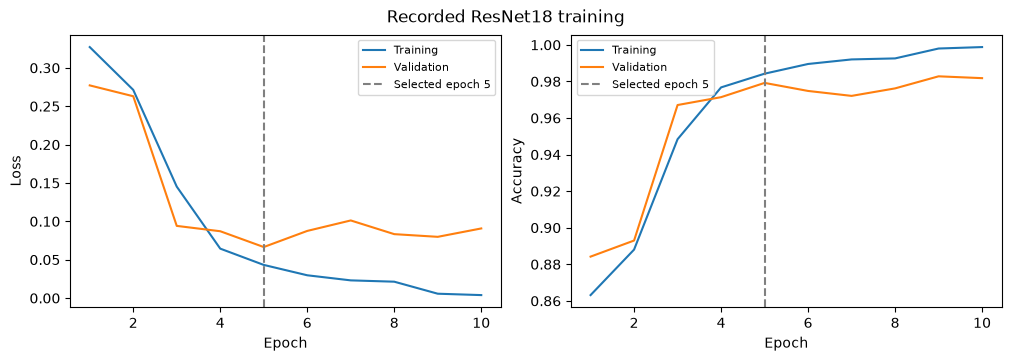

In [13]:
# Plot the same loss and accuracy values from the table.
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(epochs, [row[f"train_{metric}"] for row in history], label="Training")
    ax.plot(epochs, [row[f"val_{metric}"] for row in history], label="Validation")
    ax.axvline(selected_epoch, color="grey", ls="--", label=f"Selected epoch {selected_epoch}")
    ax.set(xlabel="Epoch", ylabel=metric.title())
    ax.legend(fontsize=8)
fig.suptitle(f"Recorded {MODEL_NAME} training")
h.show_plot()


**Why we chose epoch 5.** It had the lowest validation loss
(0.0665), with 97.92% validation accuracy.
Epoch 9 reached a higher validation accuracy of
98.28%, but its validation loss was worse
(0.0798), so it did not replace the selected checkpoint.

Accuracy counts correct labels at the fixed 0.5 threshold. Binary cross-entropy loss also
considers confidence and penalizes confident wrong answers. We chose this loss-based rule
before selecting an epoch. The test set was used only to evaluate the selected weights.

Training stopped after epoch 10, following five epochs without a validation-loss
improvement of at least 0.0001. The later behaviour plots use epoch 5, not the final epoch.

The first two epochs trained only the new classifier; full fine-tuning began at epoch 3.


In [14]:
# These scores document training; the next figures investigate behaviour.
for split in ["validation", "official_test"]:
    result = report["evaluation"][split]
    print(f"{split}: {result['n']:,} images · accuracy {result['accuracy']:.2%}")


validation: 10,000 images · accuracy 97.92%
official_test: 20,000 images · accuracy 97.73%


## A2. What does an edit do to one prediction?

The saved experiment contains predictions for 10,000 validation images under 29 conditions.
We use a fixed model and threshold throughout. The image previews contain 30 examples per
label and object class. We deliberately select a fake sensitive to blur and a real image
sensitive to sharpening; these illustrate possible failures, not typical ones.


In [15]:
# Load named arrays once, then calculate the quantities used in the plots.
data = h.load_saved("phase1_behaviour_bundle.npz")
conditions = json.loads(str(data["conditions"]))
labels, objects = data["labels"], data["objects"]
logits = data["resnet_logit"]
fake_mask, real_mask = labels == 0, labels == 1
predicted_fake = logits < 0
fake_probability = 1 / (1 + np.exp(np.clip(logits, -80, 80)))
blur = h.condition_index(conditions, "Blur", 0.6)
resize = h.condition_index(conditions, "Resize", 28)
sharpen = h.condition_index(conditions, "Sharpen", 200)


In [16]:
# Choose from the included pixels using a reproducible score-change rule.
previews = dict(zip(data["thumb_indices"], data["thumb_images"]))
chosen = []
for label, condition in [(0, blur), (1, sharpen)]:
    pool = data["thumb_indices"]
    correct = predicted_fake[0, pool] == (labels[pool] == 0)
    pool = pool[correct & (labels[pool] == label)]
    change = fake_probability[condition, pool] - fake_probability[0, pool]
    position = np.argmin(change) if label == 0 else np.argmax(change)
    chosen.append(int(pool[position]))


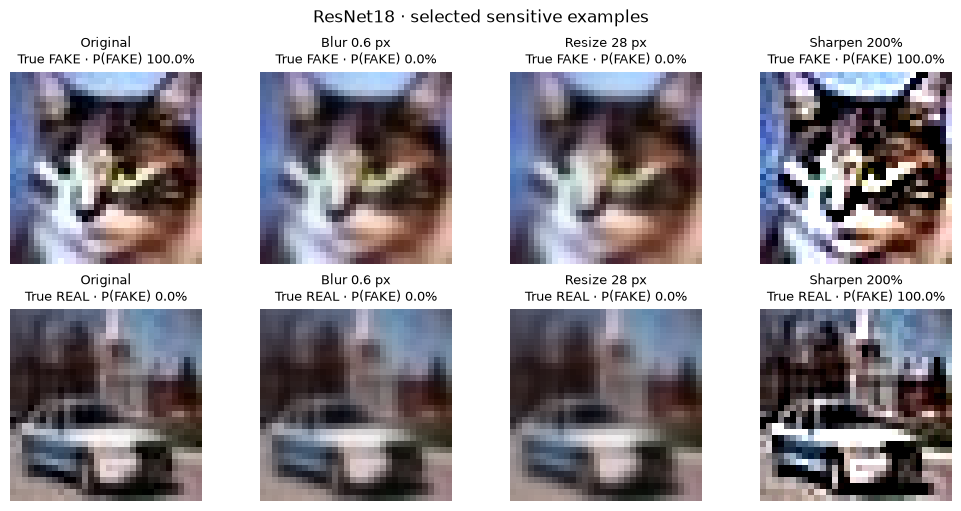

In [17]:
# Scores are saved predictions; the helper recreates exactly the corresponding pixels.
edits = [0, blur, resize, sharpen]
titles = ["Original", "Blur 0.6 px", "Resize 28 px", "Sharpen 200%"]
fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
for row, index in enumerate(chosen):
    truth = "FAKE" if labels[index] == 0 else "REAL"
    for ax, condition, title in zip(axes[row], edits, titles):
        image = h.edit_image(previews[index], conditions[condition])
        ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
        ax.set_title(f"{title}\nTrue {truth} · P(FAKE) {fake_probability[condition, index]:.1%}", fontsize=9)
        ax.axis("off")
fig.suptitle(f"{MODEL_NAME} · selected sensitive examples")
h.show_plot()


The visible subject stays recognizable, but the scores can change dramatically.
We now check whether this also happens across the full validation set.

## A3. How common are those failures?

We separate missed fakes from real photos flagged as fake. Calling everything REAL could
look good for real photos while making the detector useless for fakes. Different edit
families are shown separately because their strengths are not directly comparable.


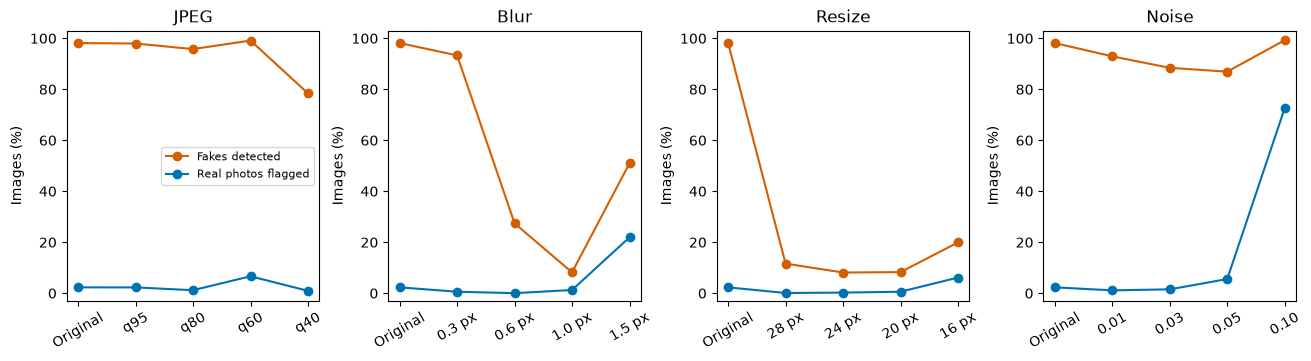

In [18]:
# Each point uses all 5,000 validation images of that label.
families = ["JPEG", "Blur", "Resize", "Noise"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5), layout="constrained")
for ax, family in zip(axes, families):
    indices = h.family_indices(conditions, family)
    for mask, color, name in [(fake_mask, h.FAKE_COLOR, "Fakes detected"),
                              (real_mask, h.REAL_COLOR, "Real photos flagged")]:
        rate = predicted_fake[indices][:, mask].mean(axis=1)
        ax.plot(range(5), 100*rate, "o-", color=color, label=name)
    ax.set(xticks=range(5), xticklabels=[conditions[i]["label"] for i in indices],
           title=family, ylabel="Images (%)", ylim=(-3, 103))
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
h.show_plot()


In [19]:
# State the main rates directly from the predictions, rather than hard-coding them.
for index, name in [(0, "Original"), (blur, "Blur 0.6"), (resize, "Resize 28")]:
    print(f"{name}: {predicted_fake[index, fake_mask].mean():.1%} of fakes detected")


Original: 98.1% of fakes detected
Blur 0.6: 27.4% of fakes detected
Resize 28: 11.6% of fakes detected


Blur and resizing cause a large loss of fake detection. The score depends on small
image details, not just whether the subject still looks similar to us.


## A4. Does every image react to blur in the same way?

The previous rate curves summarize thousands of images. Here we follow 20 individual
fake images as blur increases. Each thin grey line is one image. The thick orange line
is the mean score over all 5,000 fakes, and the dashed line is the decision threshold.
A score above 0.5 means the model still detects the fake.

We use the same seeded sample in both model notebooks, chosen before inspecting the
responses. The mean is a mean probability, not the percentage of images detected.

This follows the **ICE idea from Lecture 04, slides 20–23**: keep individual responses
visible alongside the average. Here we vary blur strength, which changes many pixels
at once, rather than independently changing one tabular feature.


In [20]:
# Pick the same 20 fake images for both models so we can compare their reactions.
blur_indices = h.family_indices(conditions, "Blur")
blur_strengths = [0] + [conditions[i]["value"] for i in blur_indices[1:]]
fake_indices = np.flatnonzero(fake_mask)
rng = np.random.default_rng(2026)
sampled_fakes = rng.choice(fake_indices, 20, replace=False)
mean_blur_score = fake_probability[blur_indices][:, fake_mask].mean(axis=1)


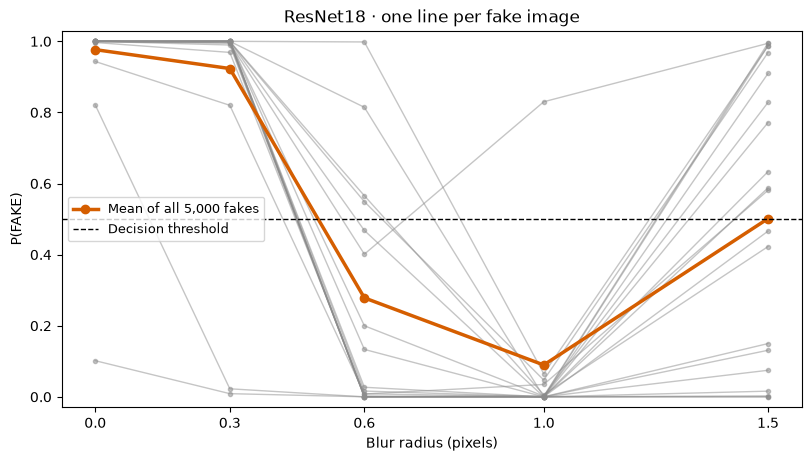

In [21]:
# Follow each image through the tested blur strengths, rather than averaging it away.
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for index in sampled_fakes:
    ax.plot(blur_strengths, fake_probability[blur_indices, index],
            color="0.55", alpha=0.5, lw=1, marker=".")

# The average uses every fake image, not just the 20 lines shown here.
ax.plot(blur_strengths, mean_blur_score, "o-", color=h.FAKE_COLOR,
        lw=2.5, label="Mean of all 5,000 fakes")
ax.axhline(0.5, color="black", ls="--", lw=1, label="Decision threshold")
ax.set(xlabel="Blur radius (pixels)", ylabel="P(FAKE)", xticks=blur_strengths,
       ylim=(-0.03, 1.03), title=f"{MODEL_NAME} · one line per fake image")
ax.legend(fontsize=9)
h.show_plot()


**What we see.** Many sampled images start with very high fake scores and drop sharply
by 0.6 px. Several then rise again at 1.5 px. Across all 5,000 fakes, the mean climbs from
about 0.09 at 1.0 px to 0.50 at 1.5 px. In this fixed sample, 19 of 20 fakes are detected
initially, only 1 at 1.0 px, and 11 at 1.5 px.

The average alone hides these different paths, including one image that already starts
below the threshold. Stronger blur does not restore detail; the rebound tells us that the
response is more complicated than a steady loss of confidence. We only measured the marked strengths.


## A5. Do blur and resizing fool the same images?

Each dot below is one of the **5,000 fake validation images**. Its horizontal position
is P(FAKE) after blur 0.6 px. Its vertical position is P(FAKE) after resizing to 28 pixels
and back. The two dashed lines split the plot into four outcomes. The dotted diagonal
marks equal scores for the two edits.

The point cloud shows which images react similarly, which react differently, and how far
their scores move apart. Two separate detection rates do not preserve that pairing.
This uses the idea from **Lecture 02, slide 7 (Anscombe's quartet)**: look at the individual
points because summary numbers can hide the structure. The two edit strengths are not
matched for equal visual change, so this compares these particular settings.


In [22]:
# Pair the two scores by image index. Every point refers to the same fake in both edits.
blur_scores = fake_probability[blur, fake_mask]
resize_scores = fake_probability[resize, fake_mask]
blur_found = predicted_fake[blur, fake_mask]
resize_found = predicted_fake[resize, fake_mask]
outcomes = [
    (0.25, 0.25, "Missed by both", (~blur_found & ~resize_found).sum()),
    (0.75, 0.25, "Only blur detects", (blur_found & ~resize_found).sum()),
    (0.25, 0.75, "Only resize detects", (~blur_found & resize_found).sum()),
    (0.75, 0.75, "Detected by both", (blur_found & resize_found).sum()),
]


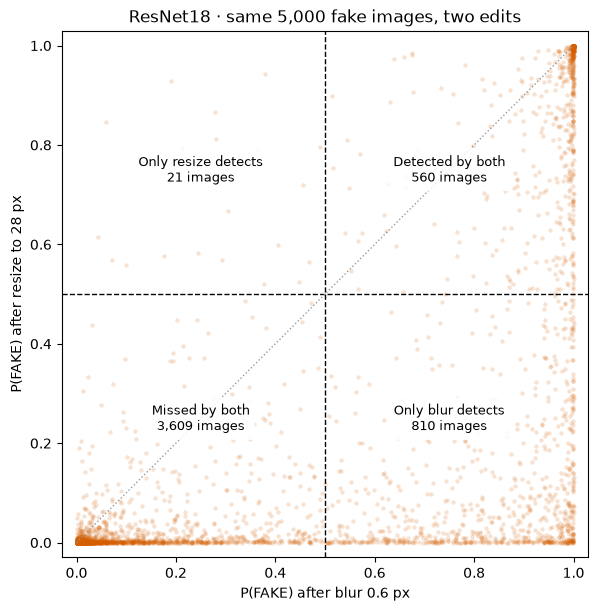

In [23]:
# Transparent points let us see dense areas without hiding the exceptions.
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ax.scatter(blur_scores, resize_scores, s=10, alpha=0.18, color=h.FAKE_COLOR, linewidths=0)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.axhline(0.5, color="black", ls="--", lw=1)
ax.plot([0, 1], [0, 1], color="0.6", ls=":", lw=1)

# Label the four outcomes so we can read the plot without remembering the axes.
for x, y, name, count in outcomes:
    ax.text(x, y, f"{name}\n{count:,} images", ha="center", va="center", fontsize=9,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
ax.set(xlabel="P(FAKE) after blur 0.6 px", ylabel="P(FAKE) after resize to 28 px",
       xlim=(-0.03, 1.03), ylim=(-0.03, 1.03), aspect="equal",
       title=f"{MODEL_NAME} · same 5,000 fake images, two edits")
h.show_plot()


**What we see.** The bottom-left group is even larger for ResNet18: **3,609 images
are missed by both edits**, and only 560 are detected by both. Another 810 survive blur
but not resizing; just 21 show the opposite pattern. The large shared group means the two
failure rates mostly concern the same fakes.

The strong concentration below the diagonal shows how much lower many fake scores become
after resizing at this setting. Some predictions are near zero under both edits, while
others disagree strongly. That difference is lost in an accuracy table. Overlapping dots
can look like one, so the labels give exact counts. The plot does not establish which
internal feature produces this shared sensitivity.


# Part B · AI-assisted follow-up

## B1. What happens if we add detail instead?

The data notebook found a sharpness difference. We now place several edits on the same
sharpness axis and test the opposite direction with sharpening. Stars mark the original images. The dashed line starts
from blurred images and adds detail back. Sharpness is measured from pixels, not activations.


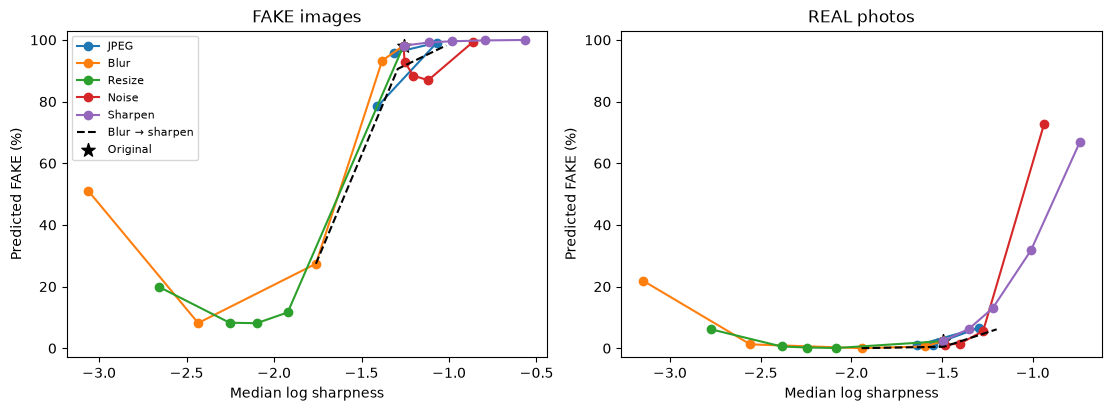

In [24]:
# These saved measurements describe each edited image.
properties = data["descriptors"].astype(np.float32)
sharpness_column = list(data["descriptor_names"]).index("log_sharpness")
restore = [blur, h.condition_index(conditions, "Blur→Sharpen", 100),
           h.condition_index(conditions, "Blur→Sharpen", 200)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, mask, name in [(axes[0], fake_mask, "FAKE images"), (axes[1], real_mask, "REAL photos")]:
    for family in families + ["Sharpen"]:
        indices = h.family_indices(conditions, family)
        sharpness = np.median(properties[indices][:, mask, sharpness_column], axis=1)
        ax.plot(sharpness, 100*predicted_fake[indices][:, mask].mean(axis=1), "o-", label=family)
    ax.plot(np.median(properties[restore][:, mask, sharpness_column], axis=1),
            100*predicted_fake[restore][:, mask].mean(axis=1), "k--", label="Blur → sharpen")
    ax.scatter(np.median(properties[0, mask, sharpness_column]),
               100*predicted_fake[0, mask].mean(), c="black", marker="*", s=100, label="Original")
    ax.set(title=name, xlabel="Median log sharpness", ylabel="Predicted FAKE (%)", ylim=(-3, 103))
axes[0].legend(fontsize=8)
h.show_plot()


Sharpening makes real photos more likely to be flagged, while sharpening blurred
fakes restores much of their detection. However, noise does not follow the same pattern.
Fine detail matters, but a single sharpness number does not fully explain the detector.

## B2. Does colour help some fakes survive blur?

We follow each object class through blur, then reduce saturation to 75% and 50%.
A multiplier of 0.5 reduces colour; it does not make the image completely grey.


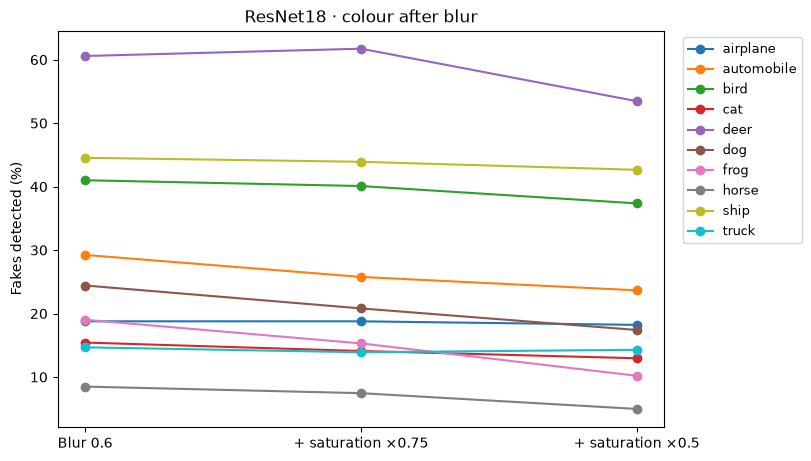

In [25]:
# Keep the same fake images through all three stages of the comparison.
chain = [blur, h.condition_index(conditions, "Blur→Desaturate", 0.75),
         h.condition_index(conditions, "Blur→Desaturate", 0.5)]
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for object_id, name in enumerate(data["object_names"]):
    mask = fake_mask & (objects == object_id)
    rates = predicted_fake[chain][:, mask].mean(axis=1)
    ax.plot(range(3), 100*rates, "o-", label=name)
ax.set(xticks=range(3), xticklabels=["Blur 0.6", "+ saturation ×0.75", "+ saturation ×0.5"],
       ylabel="Fakes detected (%)", title=f"{MODEL_NAME} · colour after blur")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
h.show_plot()


In [26]:
# Colour alone is a control: does reducing it matter before blur is added?
colour_only = [i for i, item in enumerate(conditions) if item["family"] == "Saturation"]
rates = predicted_fake[colour_only][:, fake_mask].mean(axis=1)
print(f"Fakes detected with colour-only edits: {rates.min():.1%}–{rates.max():.1%}")


Fakes detected with colour-only edits: 97.0%–98.2%


Colour-only edits change detection much less than blur followed by desaturation.
The combination suggests a secondary colour cue, especially for some CNN object classes.
These edits change multiple image properties, so this is evidence for a hypothesis, not
proof of a particular internal feature.

## What we learned

Strong clean performance does not guarantee stable predictions after small edits.
Removing fine detail hides many fakes, adding it makes real photos look fake, and colour
helps explain some differences between object classes. These are the questions we take
into Phase II, where we inspect the network.

Our scope is one selected run per model, CIFAKE's 32×32 images, and a fixed decision
threshold. The plots do not establish behaviour on larger images or unseen generators.

## Supporting check · Confidence shift or lost separation?

The main findings are above. This extra comparison asks whether resizing destroys the
ranking of REAL and FAKE scores, or mainly moves them across the fixed zero threshold.
Boxes show the middle half; whiskers show the 5th–95th percentiles. Numbers are ROC-AUC.


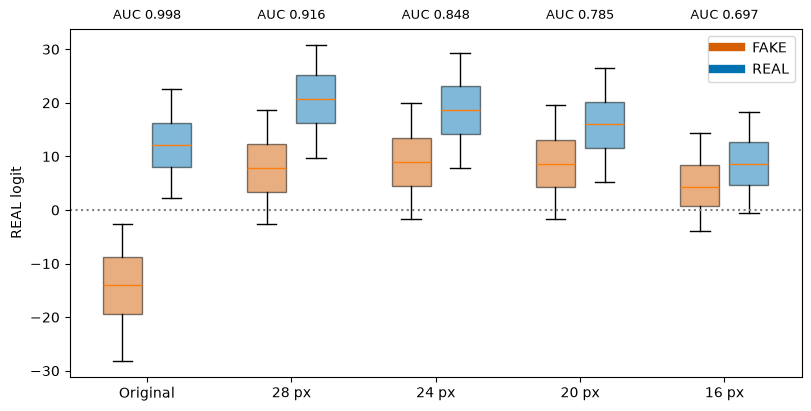

In [27]:
# Keep the distributions visible; threshold-based accuracy alone can hide a shared shift.
indices = h.family_indices(conditions, "Resize")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for offset, mask, color, name in [(-0.17, fake_mask, h.FAKE_COLOR, "FAKE"),
                                 (0.17, real_mask, h.REAL_COLOR, "REAL")]:
    boxes = ax.boxplot([logits[i, mask] for i in indices], positions=np.arange(5)+offset,
                       widths=0.27, whis=(5, 95), showfliers=False, patch_artist=True, manage_ticks=False)
    for box in boxes["boxes"]:
        box.set(facecolor=color, alpha=0.5)
    ax.plot([], [], color=color, lw=6, label=name)
for position, index in enumerate(indices):
    ax.text(position, 1.02, f"AUC {roc_auc_score(labels, logits[index]):.3f}",
            transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9)
ax.axhline(0, color="grey", ls=":")
ax.set(xticks=range(5), xticklabels=[conditions[i]["label"] for i in indices], ylabel="REAL logit")
ax.legend()
h.show_plot()


After mild resizing, ranking remains useful even though many fake scores cross the
decision threshold. That supports a confidence shift as part of the failure, rather than
complete loss of separating information. Stronger resizing also damages ranking.


### Supporting check · Compare the same images across both models

Each hexagon counts fake validation images after resizing to 28 pixels. Positive
REAL logits are mistakes on these images. This compares outputs without looking inside either model.


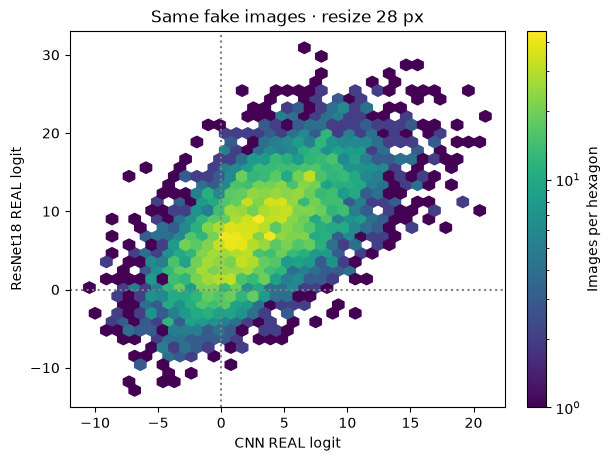

In [28]:
# Pair scores by image index, so we compare the same fakes rather than just averages.
fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
density = ax.hexbin(data["cnn_logit"][resize, fake_mask], logits[resize, fake_mask],
                    gridsize=35, bins="log", mincnt=1, cmap="viridis")
ax.axhline(0, color="grey", ls=":")
ax.axvline(0, color="grey", ls=":")
ax.set(xlabel="CNN REAL logit", ylabel="ResNet18 REAL logit", title="Same fake images · resize 28 px")
fig.colorbar(density, ax=ax, label="Images per hexagon")
h.show_plot()


The scores tend to move together, and many fakes are mistaken for real by both
models. This comparison changes architecture, initialization and preprocessing together;
it does not isolate the effect of architecture alone.
